# Modelo v2 — DenseNet121 optimizado (aumento + scheduler + early stopping)
Framework: **PyTorch** (torchvision trae DenseNet121 listo). Si se define otro framework, este notebook se porta.

## Bloque 0 — Entorno: Drive, GPU, rutas e hiperparámetros

In [1]:
# Bloque 0.1 — Montar Drive, imports, semilla y GPU
# Imports base (Drive, azar, torch, GPU): estado global que todo lo demás necesita.
# Lo específico (pandas, rutas, hiperparámetros...) se define en el bloque que lo usa.
from google.colab import drive
drive.mount('/content/drive')

import random
import numpy as np  # lo necesita np.random.seed de abajo

import torch

# Semilla fija: mismos números aleatorios en cada corrida (resultado repetible).
# Va aquí y no en otro bloque porque es ESTADO GLOBAL: rige el azar de TODO
# lo que viene después (mezclado de lotes en 1.3/3.2, pesos iniciales en 2.1).
# Moverla más abajo rompería la repetibilidad en silencio.
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# GPU: el entrenamiento corre ahí (mucho más rápido que CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('GPU disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nombre GPU:', torch.cuda.get_device_name(0))
else:
    print('AVISO: sin GPU el entrenamiento será muy lento. Actívala en Entorno > Cambiar tipo de ejecución.')
print('Dispositivo de trabajo:', device)

Mounted at /content/drive
PyTorch: 2.11.0+cu128
GPU disponible: True
Nombre GPU: Tesla T4
Dispositivo de trabajo: cuda


In [2]:
# Bloque 0.2 — Traer el ZIP del Drive al disco local
# Se copia 1 solo archivo seguido (rápido). Si ya está con igual tamaño, se reutiliza.
import shutil
import time
from pathlib import Path  # rutas locales y del Drive
from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)

DRIVE_DATASETS = Path('/content/drive/MyDrive/TESIS/DATASETS')

# El ZIP en Drive (nombre fijo, tal como se descargó de Kaggle)
ZIP_ORIGEN = DRIVE_DATASETS / 'rsna-pneumonia-detection-challenge.zip'
print(f'ZIP en Drive: {ZIP_ORIGEN.name} ({ZIP_ORIGEN.stat().st_size / 1e9:.2f} GB)')


def copiar_con_barra(origen, destino):
    """Copia 1 archivo grande mostrando barra, velocidad y tiempo estimado."""
    destino.parent.mkdir(parents=True, exist_ok=True)
    total = origen.stat().st_size
    t0 = time.time()
    with open(origen, 'rb') as f0, open(destino, 'wb') as f1, tqdm(total=total, unit='B', unit_scale=True, desc=f'   - {origen.name}') as barra:
        while True:
            trozo = f0.read(8 * 1024 * 1024)
            if not trozo:
                break
            f1.write(trozo)
            barra.update(len(trozo))
    shutil.copystat(origen, destino)
    print(f'   - copiado en {time.time() - t0:.0f} s.')


ZIP_LOCAL = Path('/content') / ZIP_ORIGEN.name
if ZIP_LOCAL.exists() and ZIP_LOCAL.stat().st_size == ZIP_ORIGEN.stat().st_size:
    print('ZIP ya está en local, se reutiliza.')
else:
    copiar_con_barra(ZIP_ORIGEN, ZIP_LOCAL)

ZIP en Drive: rsna-pneumonia-detection-challenge.zip (3.93 GB)


   - rsna-pneumonia-detection-challenge.zip: 100%|██████████| 3.93G/3.93G [04:15<00:00, 15.4MB/s]


   - copiado en 256 s.


In [3]:
# Bloque 0.3 — Descomprimir en local y traer los CSV de splits
# El ZIP trae su propia carpeta (rsna-pneumonia-detection-challenge/); se usa tal cual.
# Los splits v2 ya vienen filtrados del Drive (test_v2.ipynb); aquí solo se copian.
# v1 queda intacto: este notebook NUNCA lee ni escribe DATASETS/splits (solo v2).
t0 = time.time()  # inicio local: el t0 del 0.2 vive solo dentro de la función
print('Descomprimiendo/actualizando en local (extrae solo lo que falte)...')
!unzip -uq '{ZIP_LOCAL}' -d '/content'
print(f'Listo en {time.time() - t0:.0f} s.')
FUENTE_IMGS = Path('/content/rsna-pneumonia-detection-challenge/stage_2_train_images')
if not FUENTE_IMGS.exists():
    # el ZIP trajo otra estructura: se ubica donde realmente quedó
    _cands = [p for p in Path('/content').rglob('stage_2_train_images') if p.is_dir()]
    assert len(_cands) > 0, 'No se halló stage_2_train_images tras descomprimir'
    FUENTE_IMGS = _cands[0]
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,} en {FUENTE_IMGS}')
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,}')

CARPETA_SPLITS = Path('/content/splits')  # aquí se copian los 3 CSV
CARPETA_SPLITS.mkdir(parents=True, exist_ok=True)
for _n in ['train.csv', 'val.csv', 'test.csv']:
    _origen = DRIVE_DATASETS / 'v2' / 'splits' / _n
    assert _origen.exists(), f'Falta {_n} en DATASETS/v2/splits (corre test_v2.ipynb primero)'
    shutil.copy2(_origen, CARPETA_SPLITS / _n)
print('Splits en:', CARPETA_SPLITS)

Descomprimiendo/actualizando en local (extrae solo lo que falte)...
Listo en 46 s.
DICOMs locales: 26,684 en /content/stage_2_train_images
DICOMs locales: 26,684
Splits en: /content/splits


In [4]:
# Bloque 0.4 — Ruta de salida (los .npy que generará el 0.6)
CARPETA_NPY = Path('/content/dataset_filtrado')  # train/ val/ test/ con .npy
print('NPY:', CARPETA_NPY.exists(), '(False = aún no se corre el 0.6)')
print('Todo el trabajo corre en /content.')

NPY: False (False = aún no se corre el 0.6)
Todo el trabajo corre en /content.


In [5]:
# Bloque 0.5 — Funciones de transformación (solo se definen aquí, no procesan nada)
# Convierten 1 DICOM en 1 array (3,224,224) normalizado, en 4 pasos:
#   1. leer_dicom_como_gris: .dcm -> gris 0-255
#   2. redimensionar: 1024 -> 224
#   3. gris_a_rgb: 1 canal -> 3 canales
#   4. normalizar_imagenet: 0-255 -> escala ImageNet
# (Idénticas a las del Bloque 2 de test.ipynb; el 0.6 las aplica a todo.)

from PIL import Image  # aquí se redimensiona

# Media y desviación de ImageNet (las que espera DenseNet121 preentrenado).
# Se definen aquí porque solo se usan al normalizar.
MEDIA_IMAGENET = np.array([0.485, 0.456, 0.406], dtype=np.float32)
DESV_IMAGENET = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def leer_dicom_como_gris(ruta_dicom):
    """Paso 1: lee un .dcm y devuelve array uint8 de 0-255 en escala de grises."""
    import pydicom
    ds = pydicom.dcmread(str(ruta_dicom))
    img = ds.pixel_array
    if str(ds.get('PhotometricInterpretation', '')) == 'MONOCHROME1':
        img = 255 - img  # fondo negro -> fondo blanco (estándar radiológico)
    img = img.astype(np.float32)
    if img.max() > 255:  # por si algún DICOM trae 16 bits
        img = img / img.max() * 255.0
    return np.clip(img, 0, 255).astype(np.uint8)


def redimensionar(imagen_gris, tamano=224):
    """Paso 2: achica la imagen al tamaño que pide DenseNet121 (224x224)."""
    return np.array(Image.fromarray(imagen_gris).resize((tamano, tamano), Image.BILINEAR))


def gris_a_rgb(imagen_gris):
    """Paso 3: copia el gris en 3 canales RGB (0-1)."""
    rgb = np.stack([imagen_gris, imagen_gris, imagen_gris], axis=0)
    return rgb.astype(np.float32) / 255.0


def normalizar_imagenet(imagen_rgb):
    """Paso 4: ajusta los valores con media/desviación de ImageNet."""
    return (imagen_rgb - MEDIA_IMAGENET[:, None, None]) / DESV_IMAGENET[:, None, None]


def preprocesar_imagen(ruta_dicom, tamano=224):
    """Aplica los 4 pasos en orden: DICOM -> array (3, tamano, tamano) normalizado."""
    gris = leer_dicom_como_gris(ruta_dicom)
    gris_224 = redimensionar(gris, tamano)
    rgb = gris_a_rgb(gris_224)
    return normalizar_imagenet(rgb)


print('Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.')

Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.


In [6]:
# Bloque 0.6 — Generar los .npy en el disco local
# Recorre los 3 CSV y transforma SOLO lo que dicen (14,013 imágenes, no todo el ZIP).
# Muestra barra por split; si se cortó antes, continúa donde quedó (valida contenido, no solo existencia).
!pip install -q pydicom  # se instala aquí porque solo este bloque lee DICOMs
import pandas as pd  # aquí se leen los CSV de splits

def archivo_valido(ruta):
    """True si el .npy existe, pesa >0 y abre con forma (3,224,224)."""
    try:
        if not ruta.exists() or ruta.stat().st_size == 0:
            return False
        return np.load(ruta).shape == (3, 224, 224)
    except Exception:
        return False


def exportar_local():
    """Genera los .npy en disco local; regenera los vacíos o corruptos."""
    from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)
    for split in ['train', 'val', 'test']:
        df_split = pd.read_csv(CARPETA_SPLITS / f'{split}.csv')
        carpeta = CARPETA_NPY / split
        carpeta.mkdir(parents=True, exist_ok=True)
        # Verifica uno por uno: una interrupción deja archivos vacíos a medias
        pendientes = []
        for _, fila in tqdm(df_split.iterrows(), total=len(df_split), desc=f'   - verificar {split}'):
            if not archivo_valido(carpeta / f"{fila['patientId']}.npy"):
                pendientes.append(fila)
        print(f'   - {split}: {len(df_split):,} total | válidos {len(df_split) - len(pendientes):,} | a generar {len(pendientes):,}')
        for fila in tqdm(pendientes, desc=f'   - generar {split}'):
            arr = preprocesar_imagen(FUENTE_IMGS / f"{fila['patientId']}.dcm")
            np.save(carpeta / f"{fila['patientId']}.npy", arr)
        print(f'   - {split} OK en {carpeta}')


# Genera los .npy locales (solo transforma lo que dicen los CSV de splits).
exportar_local()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.8 MB/s eta 0:00:00


   - verificar train: 100%|██████████| 9807/9807 [00:00<00:00, 11734.46it/s]


   - train: 9,807 total | válidos 0 | a generar 9,807


   - generar train: 100%|██████████| 9807/9807 [02:15<00:00, 72.57it/s]


   - train OK en /content/dataset_filtrado/train


   - verificar val: 100%|██████████| 2102/2102 [00:00<00:00, 12462.84it/s]


... (3 outputs left out)

   - verificar test: 100%|██████████| 2104/2104 [00:00<00:00, 13213.23it/s]


   - test: 2,104 total | válidos 0 | a generar 2,104


   - generar test: 100%|██████████| 2104/2104 [00:27<00:00, 76.21it/s]

   - test OK en /content/dataset_filtrado/test


## Bloque 1 — Datos: CSV + .npy → cargadores

In [7]:
# Bloque 1.1 — Cargar los 3 CSV y verificar que todo calce
df_train = pd.read_csv(CARPETA_SPLITS / 'train.csv')
df_val = pd.read_csv(CARPETA_SPLITS / 'val.csv')
df_test = pd.read_csv(CARPETA_SPLITS / 'test.csv')

for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{nombre}: {len(df):,} filas | neumonía={df["etiqueta"].mean():.2%}')

# Verificación: cada fila del CSV debe tener su .npy en la carpeta que le toca
for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    n_npy = len(list((CARPETA_NPY / nombre).glob('*.npy')))
    print(f'{nombre}: {n_npy:,} archivos .npy')
    assert n_npy == len(df), f'Faltan .npy en {nombre} (corre el Bloque 0.6)'
print('Verificación OK: todo CSV tiene sus imágenes.')

train: 9,807 filas | neumonía=40.15%
val: 2,102 filas | neumonía=40.15%
test: 2,104 filas | neumonía=40.16%
train: 9,807 archivos .npy
val: 2,102 archivos .npy
test: 2,104 archivos .npy
Verificación OK: todo CSV tiene sus imágenes.


In [8]:
# Bloque 1.2 — Lector de datos: convierte cada fila del CSV en (imagen, etiqueta)
# El modelo no come archivos: esta clase carga el .npy y lo entrega como tensor.
# Novedad v2: el train aplica aumento (flip + rotación leve) en memoria, en cada época.
# Val/test van sin aumento (medición limpia). No se guardan imágenes aumentadas.
from torch.utils.data import Dataset, DataLoader  # aquí se define el lector que los usa
from torchvision import transforms as T  # aquí vive el aumento (solo train)

AUMENTO_TRAIN = T.Compose([  # geométrico leve: no inventa anatomía, solo varía la vista
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=8, interpolation=T.InterpolationMode.BILINEAR),
])


class RadioDataset(Dataset):
    """Lee .npy (3,224,224) + etiqueta (0/1) a partir de un CSV de split."""
    def __init__(self, df, carpeta_npy, aumentar=False):
        self.df = df.reset_index(drop=True)
        self.carpeta_npy = Path(carpeta_npy)
        self.aumentar = aumentar  # True solo en train

    def __len__(self):
        return len(self.df)  # cuántas imágenes hay

    def __getitem__(self, i):
        # i = número de fila: se busca su .npy y su etiqueta
        fila = self.df.iloc[i]
        imagen = torch.from_numpy(np.load(self.carpeta_npy / f"{fila['patientId']}.npy"))
        if self.aumentar:
            imagen = AUMENTO_TRAIN(imagen)
        etiqueta = torch.tensor(float(fila['etiqueta']))
        return imagen, etiqueta

print('Clase RadioDataset definida (aún no lee nada, solo es el molde).')
print('Aumento train:', AUMENTO_TRAIN)


Clase RadioDataset definida (aún no lee nada, solo es el molde).
Aumento train: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-8.0, 8.0], interpolation=bilinear, expand=False, fill=0)
)


In [9]:
# Bloque 1.3 — Armar los 3 cargadores y probar con un lote
# train se mezcla (shuffle) en cada época; val/test van en orden fijo.
BATCH = 32       # imágenes por lote: 32 cabe bien en la GPU gratis de Colab
TRABAJADORES = 2 # hilos que cargan imágenes mientras la GPU entrena
ds_train = RadioDataset(df_train, CARPETA_NPY / 'train', aumentar=True)  # v2: aumento aquí
ds_val = RadioDataset(df_val, CARPETA_NPY / 'val')
ds_test = RadioDataset(df_test, CARPETA_NPY / 'test')

en_gpu = (device.type == 'cuda')
cargar_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_val = DataLoader(ds_val, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_test = DataLoader(ds_test, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)

# Prueba: un lote del train. Forma esperada: (32 imágenes, 3 canales, 224, 224)
imagenes, etiquetas = next(iter(cargar_train))
print('Lote imágenes:', tuple(imagenes.shape), '| Lote etiquetas:', tuple(etiquetas.shape))
print('Etiquetas del lote:', etiquetas.int().tolist())
assert tuple(imagenes.shape[1:]) == (3, 224, 224), 'Forma inesperada en las imágenes'
print(f'Lotes por época -> train: {len(cargar_train)}, val: {len(cargar_val)}, test: {len(cargar_test)}')

Lote imágenes: (32, 3, 224, 224) | Lote etiquetas: (32,)
Etiquetas del lote: [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1]
Lotes por época -> train: 307, val: 66, test: 66


## Bloque 2 — Modelo: DenseNet121 preentrenado + regla de aprendizaje

In [10]:
# Bloque 2.1 — Modelo v1: DenseNet121 preentrenado, adaptado a 1 salida
# Transfer learning en simple: el modelo ya sabe "ver" (aprendió con ImageNet)
# y solo se le cambia la última capa para que responda sí/no neumonía.
# (Los pesos se descargan solos la primera vez, ~30 MB.)
from torchvision import models  # aquí se crea el DenseNet121
import torch.nn as nn  # aquí se reemplaza su última capa
modelo = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# La última capa original responde 1000 clases de fotos; se reemplaza por 1 neurona
n_entradas = modelo.classifier.in_features
modelo.classifier = nn.Linear(n_entradas, 1)
modelo = modelo.to(device)

# Cuántos números va a ajustar el entrenamiento (parámetros entrenables)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f'DenseNet121 listo en {device} | parámetros a entrenar: {n_params:,}')
print('Última capa:', modelo.classifier)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 206MB/s]


DenseNet121 listo en cuda | parámetros a entrenar: 6,954,881
Última capa: Linear(in_features=1024, out_features=1, bias=True)


In [11]:
# Bloque 2.2 — Regla de aprendizaje: pérdida + optimizador
# Hay más "sin neumonía" que "con": pos_weight equilibra para que el modelo
# no aprenda el truco de responder siempre 0. Se calcula solo desde el train.
LR = 1e-4  # paso de aprendizaje: chico porque el modelo ya viene preentrenado
n_pos = int(df_train['etiqueta'].sum())
n_neg = len(df_train) - n_pos
peso_pos = torch.tensor([n_neg / n_pos], device=device)
print(f'Train: {n_pos:,} con neumonía / {n_neg:,} sin | peso positivo = {peso_pos.item():.3f}')

# Pérdida: castiga qué tan lejos quedó la respuesta de la etiqueta real
criterio = nn.BCEWithLogitsLoss(pos_weight=peso_pos)
# Optimizador: ajusta los parámetros un poquito tras cada lote (paso = LR)
optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
# Nota v2: se mantiene pos_weight (comparable con v1); focal loss queda como experimento futuro.
print('Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR =', LR)

Train: 3,938 con neumonía / 5,869 sin | peso positivo = 1.490
Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR = 0.0001


## Bloque 3 — Entrenamiento (guarda el mejor según val)

In [12]:
# Bloque 3.1 — Funciones de entrenamiento y evaluación (solo se definen aquí)
from sklearn.metrics import roc_auc_score
UMBRAL = 0.5  # probabilidad >= 0.5 cuenta como con neumonía (1). Lo usan evaluar (3.1), test (4.1) y casos (5.3).
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)

def entrenar_epoca(modelo, cargador):
    """Una vuelta completa al train: predice, mide error, corrige. Devuelve pérdida media."""
    modelo.train()
    perdidas = []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        optimizador.zero_grad()                # borra correcciones anteriores
        salidas = modelo(imagenes).squeeze(1)  # respuesta: 1 número por imagen
        perdida = criterio(salidas, etiquetas) # qué tan mal respondió
        perdida.backward()                     # calcula cómo corregir
        optimizador.step()                     # aplica la corrección
        perdidas.append(perdida.item())
    return float(np.mean(perdidas))


@torch.no_grad()  # aquí no se corrige nada, solo se mide (más rápido)
def evaluar(modelo, cargador):
    """Pasa val/test SIN corregir. Devuelve pérdida, exactitud y AUC."""
    modelo.eval()
    perdidas, todas_prob, todas_et = [], [], []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        salidas = modelo(imagenes).squeeze(1)
        perdidas.append(criterio(salidas, etiquetas).item())
        todas_prob.extend(torch.sigmoid(salidas).cpu().tolist())  # a probabilidad 0-1
        todas_et.extend(etiquetas.cpu().tolist())
    todas_prob = np.array(todas_prob)
    todas_et = np.array(todas_et)
    pred = (todas_prob >= UMBRAL).astype(int)
    acc = float((pred == todas_et).mean())
    auc = float(roc_auc_score(todas_et, todas_prob))
    return float(np.mean(perdidas)), acc, auc

print('Funciones entrenar_epoca y evaluar definidas.')

Funciones entrenar_epoca y evaluar definidas.


In [13]:
# Bloque 3.2 — Entrenamiento optimizado (scheduler + early stopping)
# Novedades v2 vs v1: (1) el train ya trae aumento (1.3), (2) el LR baja solo si el
# AUC val se estanca, (3) se para antes si no mejora. Se sigue guardando el mejor por AUC val.
EPOCAS = 15  # máximo: con early stopping suele parar antes (en v1 lo mejor fue época 2)
PACIENCIA = 3  # épocas seguidas sin mejorar AUC val antes de parar
CARPETA_MODELOS = Path('/content/drive/MyDrive/TESIS/MODELOS')  # aquí se guarda todo lo entrenado
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
# Cada época imprime su duración y cuánto falta aprox.
import time
# Cada corrida tiene su ID (fecha-hora): ningún archivo se sobrescribe entre corridas.
from datetime import datetime
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
from torch.optim.lr_scheduler import ReduceLROnPlateau  # aquí se crea el scheduler
scheduler = ReduceLROnPlateau(optimizador, mode='max', factor=0.5, patience=2)
mejor_auc = 0.0  # se compara solo dentro de ESTA corrida
sin_mejora = 0  # contador de early stopping (solo dentro de ESTA corrida)
CARPETA_CORRIDA = CARPETA_MODELOS / f'densenet121_v2_{RUN_ID}'
CARPETA_CORRIDA.mkdir(parents=True, exist_ok=True)
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'  # el mejor DE ESTA corrida
historial = []  # una fila por época: train_loss, val_loss, val_acc, val_auc, lr

for epoca in range(1, EPOCAS + 1):
    t_ep = time.time()
    p_train = entrenar_epoca(modelo, cargar_train)
    p_val, acc_val, auc_val = evaluar(modelo, cargar_val)
    lr_ahora = float(optimizador.param_groups[0]['lr'])  # LR usado en ESTA época
    historial.append({'epoca': epoca, 'train_loss': p_train, 'val_loss': p_val,
                      'val_acc': acc_val, 'val_auc': auc_val, 'lr': lr_ahora})
    marca = ''
    if auc_val > mejor_auc:
        mejor_auc = auc_val
        torch.save(modelo.state_dict(), RUTA_MEJOR)
        marca = '  <-- GUARDADO (mejor AUC val)'
        sin_mejora = 0
    else:
        sin_mejora += 1
    scheduler.step(auc_val)  # si el AUC val se estanca, el próximo LR baja a la mitad
    dur = time.time() - t_ep
    eta_min = dur * (EPOCAS - epoca) / 60
    print(f'Época {epoca}/{EPOCAS} | train_loss={p_train:.4f} | val_loss={p_val:.4f} | val_acc={acc_val:.4f} | val_auc={auc_val:.4f} | lr={lr_ahora:.0e} | {dur:.0f}s (~faltan {eta_min:.0f} min){marca}')
    if sin_mejora >= PACIENCIA:
        print(f'Parada temprana en época {epoca}: {PACIENCIA} épocas sin mejorar AUC val.')
        break

pd.DataFrame(historial).to_csv(CARPETA_CORRIDA / 'historial.csv', index=False)
print(f'\nMejor AUC val: {mejor_auc:.4f} | Modelo en: {RUTA_MEJOR}')
# La carpeta final lleva fecha + mejor AUC (ej: ..._20260909_153015_auc9865)
CARPETA_FINAL = CARPETA_MODELOS / f"densenet121_v2_{RUN_ID}_auc{str(round(mejor_auc, 4)).replace('0.', '')}"
CARPETA_CORRIDA.rename(CARPETA_FINAL)
CARPETA_CORRIDA = CARPETA_FINAL
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'
print(f'Carpeta de la corrida: {CARPETA_CORRIDA}')


Época 1/15 | train_loss=0.2586 | val_loss=0.2264 | val_acc=0.9386 | val_auc=0.9792 | lr=1e-04 | 110s (~faltan 26 min)  <-- GUARDADO (mejor AUC val)
Época 2/15 | train_loss=0.1873 | val_loss=0.1982 | val_acc=0.9443 | val_auc=0.9820 | lr=1e-04 | 122s (~faltan 26 min)  <-- GUARDADO (mejor AUC val)
Época 3/15 | train_loss=0.1533 | val_loss=0.1953 | val_acc=0.9429 | val_auc=0.9824 | lr=1e-04 | 123s (~faltan 25 min)  <-- GUARDADO (mejor AUC val)
Época 4/15 | train_loss=0.1363 | val_loss=0.2130 | val_acc=0.9401 | val_auc=0.9844 | lr=1e-04 | 123s (~faltan 22 min)  <-- GUARDADO (mejor AUC val)
Época 5/15 | train_loss=0.1294 | val_loss=0.2501 | val_acc=0.9434 | val_auc=0.9833 | lr=1e-04 | 123s (~faltan 21 min)
Época 6/15 | train_loss=0.1021 | val_loss=0.2300 | val_acc=0.9539 | val_auc=0.9854 | lr=1e-04 | 122s (~faltan 18 min)  <-- GUARDADO (mejor AUC val)
Época 7/15 | train_loss=0.1033 | val_loss=0.2182 | val_acc=0.9524 | val_auc=0.9828 | lr=1e-04 | 122s (~faltan 16 min)
Época 8/15 | train_loss=

In [14]:
# Bloque 3.3 — Ver el historial época por época
df_hist = pd.DataFrame(historial)
print(df_hist.to_string(index=False))

 epoca  train_loss  val_loss  val_acc  val_auc     lr
     1    0.258607  0.226357 0.938630 0.979152 0.0001
     2    0.187260  0.198230 0.944339 0.981993 0.0001
     3    0.153343  0.195305 0.942912 0.982422 0.0001
     4    0.136252  0.212980 0.940057 0.984375 0.0001
     5    0.129366  0.250142 0.943387 0.983328 0.0001
     6    0.102136  0.230008 0.953853 0.985437 0.0001
     7    0.103305  0.218219 0.952426 0.982764 0.0001
     8    0.080532  0.207380 0.949572 0.984707 0.0001
     9    0.070956  0.215909 0.937678 0.984444 0.0001


## Bloque 4 — Evaluación FINAL en test (una sola vez, al final)

In [15]:
# Bloque 4.1 — Medir el mejor modelo con datos que nunca vio entrenando
# Métricas de tesis: exactitud, AUC, sensibilidad, especificidad + matriz de confusión.
from sklearn.metrics import confusion_matrix, roc_auc_score
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)
import time as _time
_t0 = _time.time()

# Evalúa el mejor DE ESTA corrida. Para otra versión, cambia RUTA_MEJOR por su archivo.
modelo.load_state_dict(torch.load(RUTA_MEJOR, map_location=device))
modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for imagenes, etiquetas in tqdm(cargar_test, desc='   - lotes test', leave=False):
        salidas = modelo(imagenes.to(device)).squeeze(1)
        probs.extend(torch.sigmoid(salidas).cpu().tolist())
        reales.extend(etiquetas.tolist())
probs = np.array(probs)
reales = np.array(reales)
pred = (probs >= UMBRAL).astype(int)

acc = float((pred == reales).mean())
auc = float(roc_auc_score(reales, probs))
tn, fp, fn, tp = confusion_matrix(reales, pred).ravel()
sens = float(tp / (tp + fn))  # sensibilidad: de los enfermos, cuántos detectó
esp = float(tn / (tn + fp))   # especificidad: de los sanos, cuántos acertó

print(f'TEST (n={len(reales):,}) | exactitud={acc:.4f} | AUC={auc:.4f} | medido en {_time.time() - _t0:.0f} s')
print(f'Sensibilidad={sens:.4f} | Especificidad={esp:.4f} (umbral={UMBRAL})')
print('Matriz de confusión [filas=real, columnas=predicho]:')
print('                 pred 0     pred 1')
print(f'  real 0 (sano):  {tn:>6,}  {fp:>9,}')
print(f'  real 1 (neum):  {fn:>6,}  {tp:>9,}')

TEST (n=2,104) | exactitud=0.9544 | AUC=0.9874 | medido en 9 s
Sensibilidad=0.9148 | Especificidad=0.9809 (umbral=0.5)
Matriz de confusión [filas=real, columnas=predicho]:
                 pred 0     pred 1
  real 0 (sano):   1,235         24
  real 1 (neum):      72        773


In [16]:
# Bloque 4.2 — Guardar métricas y curvas en Drive (evidencia para la tesis)
import json  # aquí se guardan las métricas
import matplotlib
matplotlib.use('Agg')  # dibuja sin abrir ventanas (modo Colab)
import matplotlib.pyplot as plt

resultados = {
    'modelo': 'densenet121_v2', 'corrida': RUN_ID, 'epocas': EPOCAS, 'lr': LR, 'batch': BATCH,
    'umbral': UMBRAL, 'semilla': SEMILLA,
    'test_n': int(len(reales)),
    'exactitud': round(float(acc), 4), 'auc': round(float(auc), 4),
    'sensibilidad': round(float(sens), 4), 'especificidad': round(float(esp), 4),
    'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    'mejor_auc_val': round(float(mejor_auc), 4),
}
with open(CARPETA_CORRIDA / 'metricas.json', 'w') as f:
    json.dump(resultados, f, indent=2)

# Curvas: si val empeora mientras train mejora, hay sobreajuste (se reporta en tesis)
df_hist = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_hist['epoca'], df_hist['train_loss'], label='train')
ax[0].plot(df_hist['epoca'], df_hist['val_loss'], label='val')
ax[0].set_title('Pérdida por época')
ax[0].set_xlabel('época')
ax[0].legend()
ax[1].plot(df_hist['epoca'], df_hist['val_auc'], label='AUC val', color='green')
ax[1].plot(df_hist['epoca'], df_hist['val_acc'], label='Acc val', color='orange')
ax[1].set_title('Métricas val por época')
ax[1].set_xlabel('época')
ax[1].legend()
fig.tight_layout()
fig.savefig(CARPETA_CORRIDA / 'curvas.png', dpi=150)
print('Guardado en:', CARPETA_CORRIDA)
print(json.dumps(resultados, indent=2))

Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854
{
  "modelo": "densenet121_v2",
  "corrida": "20260924_064905",
  "epocas": 15,
  "lr": 0.0001,
  "batch": 32,
  "umbral": 0.5,
  "semilla": 42,
  "test_n": 2104,
  "exactitud": 0.9544,
  "auc": 0.9874,
  "sensibilidad": 0.9148,
  "especificidad": 0.9809,
  "tn": 1235,
  "fp": 24,
  "fn": 72,
  "tp": 773,
  "mejor_auc_val": 0.9854
}


In [17]:
# Bloque 4.1t — Ajuste de umbral en validación (sin reentrenar)
# El umbral mueve sensibilidad/especificidad (el AUC no). Se barre de 0.10 a 0.90 en val.
# El test sigue reportándose en 0.5 (comparable con v1); el óptimo se informa como fila secundaria.
import json as _json43

with torch.no_grad():  # se re-mide val para guardar sus probabilidades
    modelo.eval()
    _pv, _rv = [], []
    for _img, _et in cargar_val:
        _sal = modelo(_img.to(device)).squeeze(1)
        _pv.extend(torch.sigmoid(_sal).cpu().tolist())
        _rv.extend(_et.tolist())
_pv = np.array(_pv)
_rv = np.array(_rv)

_filas_u = []  # un renglón por umbral probado
for _u in np.arange(0.10, 0.91, 0.05):
    _pr = (_pv >= _u).astype(int)
    _tp = int(((_pr == 1) & (_rv == 1)).sum())
    _fn = int(((_pr == 0) & (_rv == 1)).sum())
    _tn = int(((_pr == 0) & (_rv == 0)).sum())
    _fp = int(((_pr == 1) & (_rv == 0)).sum())
    _sens = _tp / (_tp + _fn)
    _esp = _tn / (_tn + _fp)
    _f1 = 2 * _tp / (2 * _tp + _fp + _fn)
    _filas_u.append((round(float(_u), 2), round(_sens, 4), round(_esp, 4),
                     round(_f1, 4), round(_sens + _esp - 1, 4)))
df_umb = pd.DataFrame(_filas_u, columns=['umbral', 'sensibilidad', 'especificidad', 'f1', 'youden'])
u_youden = float(df_umb.loc[df_umb['youden'].idxmax(), 'umbral'])
u_f1 = float(df_umb.loc[df_umb['f1'].idxmax(), 'umbral'])
print(df_umb.to_string(index=False))
print(f'Umbral por Youden: {u_youden} | Umbral por mejor F1: {u_f1}')

# Test secundario con el umbral Youden (el primario en 0.5 queda en 4.1/5.4 para comparar)
_pred_u = (probs >= u_youden).astype(int)
_tn_u = int(((_pred_u == 0) & (reales == 0)).sum())
_fp_u = int(((_pred_u == 1) & (reales == 0)).sum())
_fn_u = int(((_pred_u == 0) & (reales == 1)).sum())
_tp_u = int(((_pred_u == 1) & (reales == 1)).sum())
opt = {'umbral_reporte': float(UMBRAL), 'umbral_youden': u_youden, 'umbral_f1': u_f1,
       'test_en_umbral_youden': {'exactitud': round(float((_pred_u == reales).mean()), 4),
                                 'sensibilidad': round(_tp_u / (_tp_u + _fn_u), 4),
                                 'especificidad': round(_tn_u / (_tn_u + _fp_u), 4),
                                 'f1': round(2 * _tp_u / (2 * _tp_u + _fp_u + _fn_u), 4),
                                 'tn': _tn_u, 'fp': _fp_u, 'fn': _fn_u, 'tp': _tp_u}}
with open(CARPETA_CORRIDA / 'umbral_optimo.json', 'w') as _f:
    _json43.dump(opt, _f, indent=2)
print('Test en umbral Youden:', opt['test_en_umbral_youden'])
print('Guardado en:', CARPETA_CORRIDA / 'umbral_optimo.json')


 umbral  sensibilidad  especificidad     f1  youden
   0.10        0.9502         0.9459 0.9358  0.8962
   0.15        0.9419         0.9571 0.9392  0.8990
   0.20        0.9384         0.9634 0.9417  0.9018
   0.25        0.9348         0.9674 0.9427  0.9022
   0.30        0.9289         0.9722 0.9429  0.9011
   0.35        0.9277         0.9738 0.9434  0.9015
   0.40        0.9218         0.9762 0.9419  0.8980
   0.45        0.9218         0.9785 0.9436  0.9003
   0.50        0.9135         0.9809 0.9408  0.8944
   0.55        0.9076         0.9817 0.9382  0.8893
   0.60        0.9017         0.9825 0.9355  0.8842
   0.65        0.8981         0.9849 0.9352  0.8830
   0.70        0.8898         0.9857 0.9312  0.8755
   0.75        0.8851         0.9873 0.9297  0.8724
   0.80        0.8732         0.9881 0.9236  0.8613
   0.85        0.8649         0.9889 0.9194  0.8538
   0.90        0.8436         0.9905 0.9082  0.8341
Umbral por Youden: 0.25 | Umbral por mejor F1: 0.45
Test en umbr

## Bloque 5 — Evaluación visual y extendida

Curvas, métricas de clasificación y prueba con pacientes al azar. Todo se guarda en Drive y se muestra aquí.

AUC=0.9874 | AP=0.9857 | Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854/curvas_eval.png


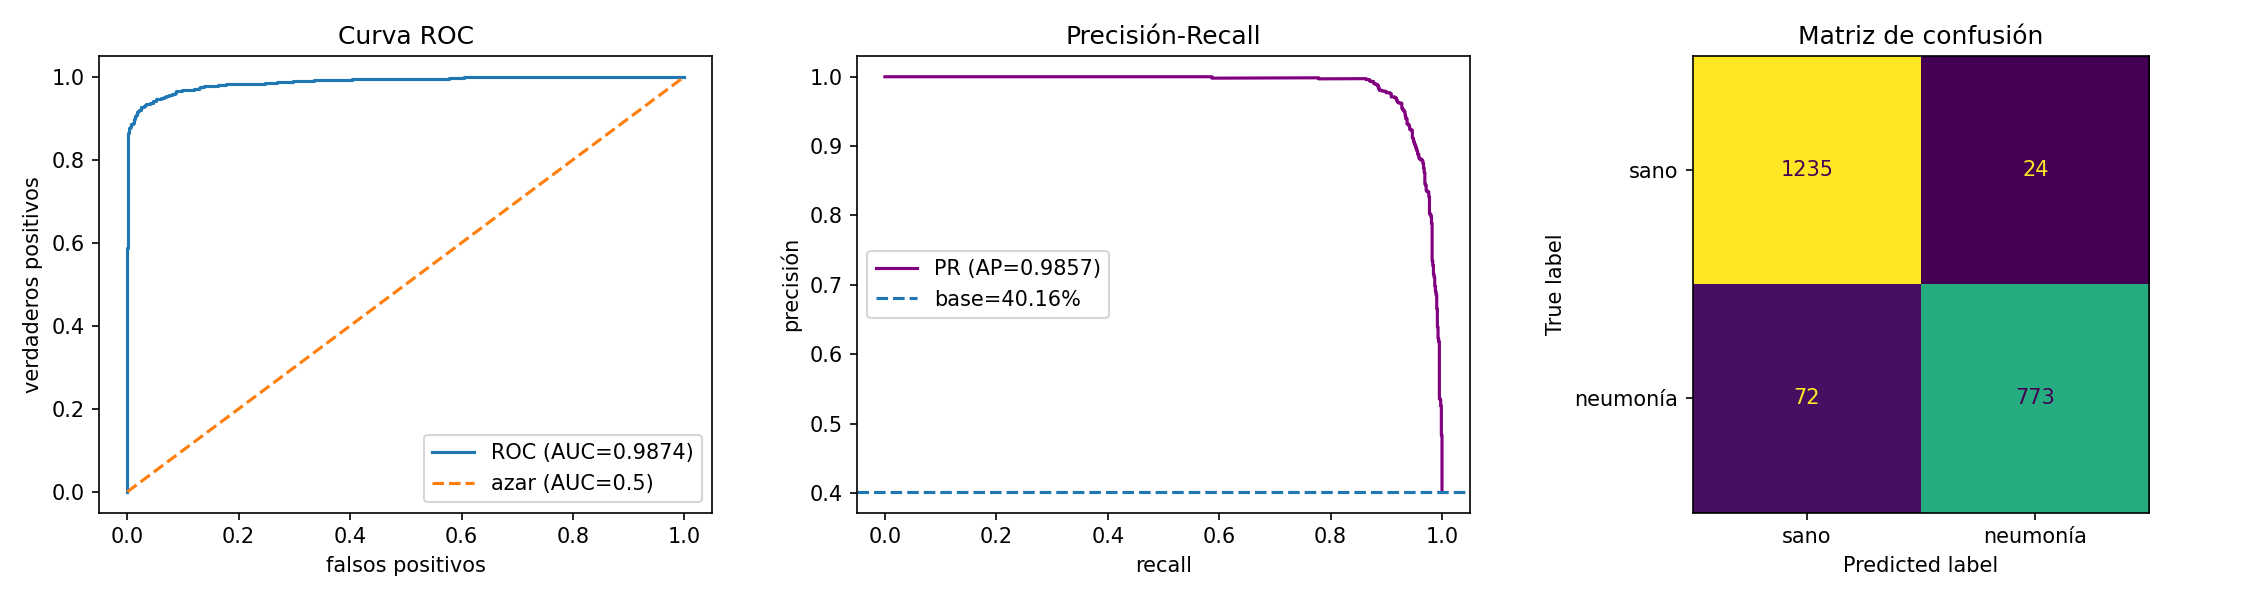

In [18]:
# Bloque 5.1 — Curvas ROC, precisión-recall y matriz de confusión
# Se guardan en Drive y se muestran aquí (display, no plt.show: vale en cualquier backend).
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

fpr, tpr, _ = roc_curve(reales, probs)  # ROC: qué tan bien separa sanos de enfermos
prec_c, rec_c, _ = precision_recall_curve(reales, probs)  # PR: útil con clases desbalanceadas
ap = float(average_precision_score(reales, probs))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(fpr, tpr, label=f'ROC (AUC={auc:.4f})')
ax[0].plot([0, 1], [0, 1], '--', label='azar (AUC=0.5)')
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('falsos positivos')
ax[0].set_ylabel('verdaderos positivos')
ax[0].legend()
ax[1].plot(rec_c, prec_c, label=f'PR (AP={ap:.4f})', color='purple')
ax[1].axhline(reales.mean(), linestyle='--', label=f'base={reales.mean():.2%}')
ax[1].set_title('Precisión-Recall')
ax[1].set_xlabel('recall')
ax[1].set_ylabel('precisión')
ax[1].legend()
ConfusionMatrixDisplay.from_predictions(reales, pred, display_labels=['sano', 'neumonía'], ax=ax[2], colorbar=False)
ax[2].set_title('Matriz de confusión')
fig.tight_layout()
RUTA_CURVAS_EVAL = CARPETA_CORRIDA / 'curvas_eval.png'
fig.savefig(RUTA_CURVAS_EVAL, dpi=150)
plt.close(fig)
print(f'AUC={auc:.4f} | AP={ap:.4f} | Guardada en: {RUTA_CURVAS_EVAL}')
display(MostrarImagen(str(RUTA_CURVAS_EVAL)))

In [19]:
# Bloque 5.2 — Métricas extendidas: precisión, recall, F1 y reporte por clase
# Precisión: de los que dijo 'sí', cuántos acertó. Recall (=sensibilidad): de los enfermos, cuántos detectó.
# F1: promedio de ambas (resume el equilibrio). Se imprimen y se guardan en JSON.
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import json as _json

precision = float(precision_score(reales, pred))
recall = float(recall_score(reales, pred))
f1 = float(f1_score(reales, pred))
print(f'Precisión={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f} | Especificidad={esp:.4f}')
print()
print(classification_report(reales, pred, target_names=['sano (0)', 'neumonía (1)'], digits=4))
ext = {'precision': round(precision, 4), 'recall': round(recall, 4), 'f1': round(f1, 4),
       'average_precision': round(float(ap), 4)}
with open(CARPETA_CORRIDA / 'metricas_extendidas.json', 'w') as f:
    _json.dump(ext, f, indent=2)
print('Guardadas en:', CARPETA_CORRIDA / 'metricas_extendidas.json')

Precisión=0.9699 | Recall=0.9148 | F1=0.9415 | Especificidad=0.9809

              precision    recall  f1-score   support

    sano (0)     0.9449    0.9809    0.9626      1259
neumonía (1)     0.9699    0.9148    0.9415       845

    accuracy                         0.9544      2104
   macro avg     0.9574    0.9479    0.9521      2104
weighted avg     0.9549    0.9544    0.9541      2104

Guardadas en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854/metricas_extendidas.json


Aciertos en la muestra: 6/6

Detalle de la muestra:
#  paciente  real      predicho  prob.  resultado
1  9f51baeb  sano      sano      0%     ✓ acierto
2  b2c534fd  sano      sano      0%     ✓ acierto
3  e314d288  sano      sano      0%     ✓ acierto
4  f125b9c8  neumonía  neumonía  100%   ✓ acierto
5  a887251c  neumonía  neumonía  100%   ✓ acierto
6  bfd795ae  neumonía  neumonía  100%   ✓ acierto
Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854/casos_azar.png


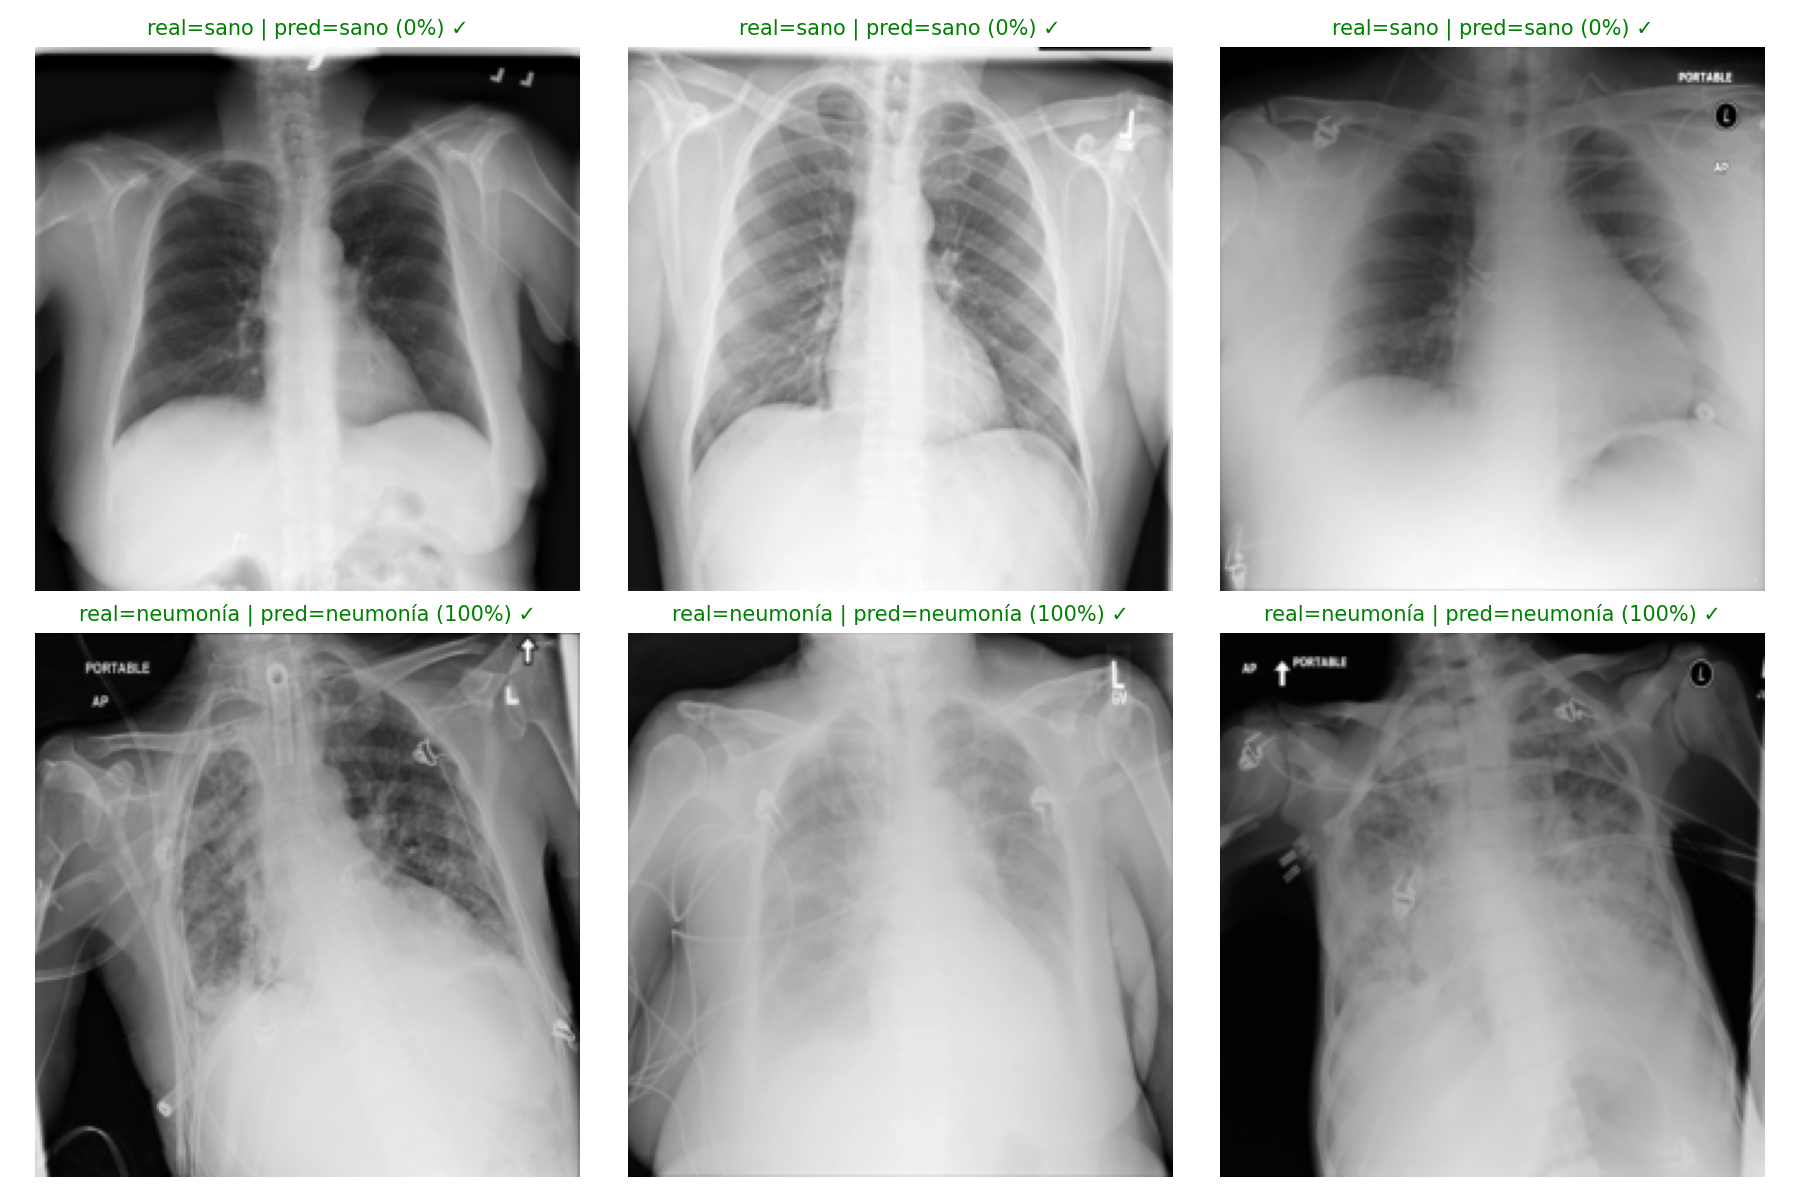

In [20]:
# Bloque 5.3 — Prueba con 6 pacientes al azar: ¿detecta bien?
# Muestra la radiografía con su etiqueta real y lo que predijo el modelo (verde=acierto, rojo=fallo).
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

def mostrar_gris(arr_norm):
    """Quita la normalización para ver la radiografía como gris 0-1."""
    img = arr_norm * DESV_IMAGENET[:, None, None] + MEDIA_IMAGENET[:, None, None]
    return np.clip(img[0], 0, 1)


rng = np.random.default_rng(7)  # semilla fija: siempre salen los mismos 6
idxs = rng.choice(len(df_test), size=6, replace=False)
filas = []  # para la tabla resumen (se imprime abajo)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.ravel(), idxs):
    pid = df_test.iloc[i]['patientId']
    arr = np.load(CARPETA_NPY / 'test' / f'{pid}.npy')
    ax.imshow(mostrar_gris(arr), cmap='gray')
    ax.axis('off')
    r, p = int(reales[i]), float(probs[i])
    bien = pred[i] == r
    filas.append((pid[:8], r, p >= UMBRAL, float(p), bool(bien)))
    ax.set_title(f"real={'neumonía' if r else 'sano'} | pred={'neumonía' if p >= UMBRAL else 'sano'} ({p:.0%}) {'✓' if bien else '✗'}",
                 color='green' if bien else 'red', fontsize=10)
fig.tight_layout()
RUTA_CASOS = CARPETA_CORRIDA / 'casos_azar.png'
fig.savefig(RUTA_CASOS, dpi=150)
plt.close(fig)
n_ok = int(sum(pred[i] == reales[i] for i in idxs))
print(f'Aciertos en la muestra: {n_ok}/6')
print('\nDetalle de la muestra:')
print(f"{'#':<3}{'paciente':<10}{'real':<10}{'predicho':<10}{'prob.':<7}resultado")
for k, (corto, r, pp, p, bien) in enumerate(filas, 1):
    print(f"{k:<3}{corto:<10}{'neumonía' if r else 'sano':<10}{'neumonía' if pp else 'sano':<10}{p:<7.0%}{'✓ acierto' if bien else '✗ fallo'}")
print('Guardada en:', RUTA_CASOS)
display(MostrarImagen(str(RUTA_CASOS)))

In [21]:
# Bloque 5.4 — Tabla resumen final: todas las métricas en un cuadro
# No calcula nada nuevo, solo junta lo ya medido en 4.1 y 5.2 para copiar a la tesis.
from IPython.display import display  # aquí se muestra la tabla
import json as _json54  # aquí se guarda el JSON final

resumen = [
    ('Exactitud (accuracy)', round(float(acc), 4)),
    ('AUC ROC', round(float(auc), 4)),
    ('AP (área bajo PR)', round(float(ap), 4)),
    ('Sensibilidad (= recall)', round(float(sens), 4)),
    ('Especificidad', round(float(esp), 4)),
    ('Precisión', round(float(precision), 4)),
    ('F1', round(float(f1), 4)),
    ('TN (sanos bien)', int(tn)),
    ('FP (falsas alarmas)', int(fp)),
    ('FN (casos perdidos)', int(fn)),
    ('TP (detectados)', int(tp)),
    ('n test', int(len(reales))),
    ('Umbral', float(UMBRAL)),
]

df_resumen = pd.DataFrame(resumen, columns=['Métrica', 'Valor'])
display(df_resumen)

# Se guarda junto al resto de la corrida (evidencia para la tesis).
df_resumen.to_csv(CARPETA_CORRIDA / 'tabla_resumen.csv', index=False)
final = {'modelo': 'densenet121_v2', 'corrida': RUN_ID, 'epocas': EPOCAS, 'lr': LR, 'batch': BATCH,
         'umbral': float(UMBRAL), 'semilla': SEMILLA, 'mejor_auc_val': round(float(mejor_auc), 4)}
for _nombre, _valor in resumen:
    final[_nombre] = _valor
with open(CARPETA_CORRIDA / 'metricas_final.json', 'w') as f:
    _json54.dump(final, f, indent=2, ensure_ascii=False)
print('Guardado en:', CARPETA_CORRIDA / 'tabla_resumen.csv', 'y metricas_final.json')

,Métrica,Valor
0,Exactitud (accuracy),0.9544
1,AUC ROC,0.9874
2,AP (área bajo PR),0.9857
3,Sensibilidad (= recall),0.9148
4,Especificidad,0.9809
5,Precisión,0.9699
6,F1,0.9415
7,TN (sanos bien),1235.0000
8,FP (falsas alarmas),24.0000
9,FN (casos perdidos),72.0000


Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854/tabla_resumen.csv y metricas_final.json


In [22]:
# Bloque 5.5 — Costo computacional: qué tan caro es (no qué tan bien clasifica)
# El rendimiento ya quedó en 5.4. Aquí solo costo: parámetros, peso del .pth y velocidad.
# OJO: el tiempo por época solo se imprimió en la consola del 3.2 (no quedó en historial.csv).
# Para ESTA corrida cópialo de la salida; desde la próxima corrida se guarda solo.
import time as _time55  # aquí se cronometra la inferencia
from IPython.display import display as _mostrar55  # aquí se muestra la tabla
import json as _json55  # aquí se guarda el JSON de costo

try:
    n_params55 = int(n_params)  # ya contado en 2.1
except NameError:
    n_params55 = int(sum(p.numel() for p in modelo.parameters() if p.requires_grad))
tam_mb55 = RUTA_MEJOR.stat().st_size / 1e6 if RUTA_MEJOR.exists() else float('nan')
gpu55 = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'

# Velocidad de inferencia: 1 pasada completa al test, sin corregir, midiendo tiempo real.
# Incluye la carga de datos (es el costo de punta a punta). En GPU se sincroniza para medir bien.
modelo.eval()
lote0, _ = next(iter(cargar_test))
lote0 = lote0.to(device)
with torch.no_grad():
    for _ in range(5):  # calentamiento: la primera pasada siempre es más lenta
        _ = modelo(lote0)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_ini55 = _time55.perf_counter()
    n_imgs55 = 0
    for imagenes, _et in cargar_test:
        imagenes = imagenes.to(device)
        _ = modelo(imagenes)
        n_imgs55 += imagenes.size(0)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_fin55 = _time55.perf_counter()
ms_img55 = (t_fin55 - t_ini55) / max(n_imgs55, 1) * 1000.0

costo = [
    ('Parámetros entrenables', n_params55),
    ('Peso best.pth (MB)', round(float(tam_mb55), 2)),
    ('GPU / dispositivo', f'{gpu55} ({device})'),
    ('Test medido (imágenes)', int(n_imgs55)),
    ('ms por imagen (inferencia)', round(float(ms_img55), 2)),
    ('imágenes por segundo', round(1000.0 / float(ms_img55), 1) if ms_img55 > 0 else None),
]

df_costo = pd.DataFrame(costo, columns=['Costo', 'Valor'])
_mostrar55(df_costo)

# Se guarda junto al resto de la corrida (evidencia para la tesis).
df_costo.to_csv(CARPETA_CORRIDA / 'tabla_costo.csv', index=False)
with open(CARPETA_CORRIDA / 'metricas_costo.json', 'w') as f:
    _json55.dump({k: v for k, v in costo}, f, indent=2, ensure_ascii=False)
print('Guardado en:', CARPETA_CORRIDA / 'tabla_costo.csv', 'y metricas_costo.json')


,Costo,Valor
0,Parámetros entrenables,6954881
1,Peso best.pth (MB),28.38
2,GPU / dispositivo,Tesla T4 (cuda)
3,Test medido (imágenes),2104
4,ms por imagen (inferencia),3.75
5,imágenes por segundo,266.6


Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854/tabla_costo.csv y metricas_costo.json


In [ ]:
# Bloque 5.6 — Galería de errores: FP y FN con imagen (análisis de errores)
# No mide nada nuevo: muestra los 3 falsos positivos más seguros y los 3 falsos
# negativos más seguros (probabilidad más lejos del umbral 0.5).
# Lectura: margen chico = caso límite razonable; margen grande = falla grave.
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen56, display as _mostrar56

_r56 = np.array(reales)
_p56 = np.array(probs)
_pred56 = np.array(pred)
_margen56 = np.abs(_p56 - float(UMBRAL))
idx_fp56 = np.where((_pred56 == 1) & (_r56 == 0))[0]
idx_fn56 = np.where((_pred56 == 0) & (_r56 == 1))[0]
idx_fp56 = idx_fp56[np.argsort(-_p56[idx_fp56])][:3]  # falsas alarmas más seguras primero
idx_fn56 = idx_fn56[np.argsort(_p56[idx_fn56])][:3]  # perdidos más seguros primero
print(f"FP totales: {len(np.where((_pred56 == 1) & (_r56 == 0))[0])} | "
      f"FN totales: {len(np.where((_pred56 == 0) & (_r56 == 1))[0])}")
_err56 = (_pred56 != _r56)
print(f"Errores límite (margen<0.15): {int((_margen56[_err56] < 0.15).sum())} de {int(_err56.sum())}")


def _gris56(arr_norm):
    """Quita la normalización para ver la radiografía como gris 0-1."""
    img = arr_norm * DESV_IMAGENET[:, None, None] + MEDIA_IMAGENET[:, None, None]
    return np.clip(img[0], 0, 1)


filas56 = []  # tabla descriptiva (se imprime y se guarda)
fig56, ejes56 = plt.subplots(2, 3, figsize=(12, 8))
for _fila, (_idxs, _tipo) in enumerate([(idx_fp56, 'FP'), (idx_fn56, 'FN')]):
    for _ax, _i in zip(ejes56[_fila], _idxs):
        _pid = df_test.iloc[int(_i)]['patientId']
        _arr = np.load(CARPETA_NPY / 'test' / f'{_pid}.npy')
        _ax.imshow(_gris56(_arr), cmap='gray')
        _ax.axis('off')
        _r, _p = int(_r56[_i]), float(_p56[_i])
        _m = abs(_p - float(UMBRAL))
        _lec = 'límite' if _m < 0.15 else 'seguro'
        filas56.append((_pid[:8], _tipo, 'neumonía' if _r else 'sano',
                        'neumonía' if _p >= UMBRAL else 'sano',
                        round(_p, 2), round(_m, 2), _lec))
        _ax.set_title(f"{_tipo} | real={'neumonía' if _r else 'sano'} ({_p:.0%}, margen {_m:.2f})",
                      color='red', fontsize=10)
fig56.tight_layout()
RUTA_ERRORES = CARPETA_CORRIDA / 'casos_error.png'
fig56.savefig(RUTA_ERRORES, dpi=150)
plt.close(fig56)
df_err56 = pd.DataFrame(filas56, columns=['paciente', 'tipo', 'real', 'predicho',
                                          'prob', 'margen', 'lectura'])
df_err56.to_csv(CARPETA_CORRIDA / 'tabla_errores.csv', index=False)
print(df_err56.to_string(index=False))
print('Guardado en:', RUTA_ERRORES, 'y tabla_errores.csv')
_mostrar56(MostrarImagen56(str(RUTA_ERRORES)))
